# RQ3 — Fairness audit results

This notebook is a visualization-only consumer of the accepted RQ3 artifacts. It does not train models, run inference, choose thresholds, calculate fairness metrics, or execute bootstrap resampling. All results use the project-wide orientation `Approved = 1`. The audit is descriptive and is not causal or legal evidence of discrimination.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
MODEL_ORDER = ["lr", "rf", "xgboost", "plain_mlp", "realmlp", "tabmmini"]
MODEL_LABELS = {"lr": "LR", "rf": "RF", "xgboost": "XGBoost", "plain_mlp": "PlainMLP", "realmlp": "RealMLP", "tabmmini": "TabMmini"}
MODEL_COLORS = dict(zip(MODEL_ORDER, plt.cm.tab10.colors[:len(MODEL_ORDER)]))

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "config/dataset_b/rq3_protocol.yaml").exists())
artifact_root = project_root / "artifacts/dataset_b/rq3/rq3_fairness_20261010_01"
status = json.loads((artifact_root / "status.json").read_text(encoding="utf-8"))
if status["status"] != "PASS" or set(status["model_status"].values()) != {"PASS"}:
    raise RuntimeError("RQ3 artifacts are not accepted; visual reporting is blocked.")

audit = pd.read_csv(artifact_root / "audit_metadata.csv")
group_metrics = pd.read_csv(artifact_root / "group_metrics.csv")
gap_metrics = pd.read_csv(artifact_root / "gap_metrics.csv")
bootstrap = pd.read_csv(artifact_root / "bootstrap_summary.csv")
runtime = pd.read_csv(artifact_root / "runtime.csv")
rq1_reporting = {
    "lr": project_root / "artifacts/dataset_b/lr/final/lr_final_15f_20261002_01/reporting/rq1_metrics_long.csv",
    "rf": project_root / "artifacts/dataset_b/rf/final/rf_final_15f_20261002_01/reporting/rq1_metrics_long.csv",
    "xgboost": project_root / "artifacts/dataset_b/xgboost/final/xgb_final_15f_20261003_01/reporting/rq1_metrics_long.csv",
    "plain_mlp": project_root / "artifacts/dataset_b/plain_mlp/final/plain_mlp_final_15f_20261004_03/reporting/rq1_metrics_long.csv",
    "realmlp": project_root / "artifacts/dataset_b/realmlp/final/realmlp_final_15f_20261004_01/reporting/rq1_metrics_long.csv",
    "tabmmini": project_root / "artifacts/dataset_b/tabmmini/final/tabmmini_final_15f_20261004_01/reporting/rq1_metrics_long.csv",
}
rq1_metrics = pd.concat([pd.read_csv(path) for path in rq1_reporting.values()], ignore_index=True)
print(f"Accepted run: {status['run_id']} | Test rows: {len(audit):,} | Orientation: {status['target_orientation']}")

Accepted run: rq3_fairness_20261010_01 | Test rows: 43,996 | Orientation: Approved-positive


## Accepted run and audit coverage

,model,point_metric_seconds,bootstrap_seconds,total_seconds,status
0,LR,0.094,175.655,175.749,PASS
1,RF,0.168,160.214,160.381,PASS
2,XGBoost,0.083,87.434,87.516,PASS
3,PlainMLP,0.084,87.448,87.532,PASS
4,RealMLP,0.081,87.796,87.877,PASS
5,TabMmini,0.082,87.611,87.693,PASS


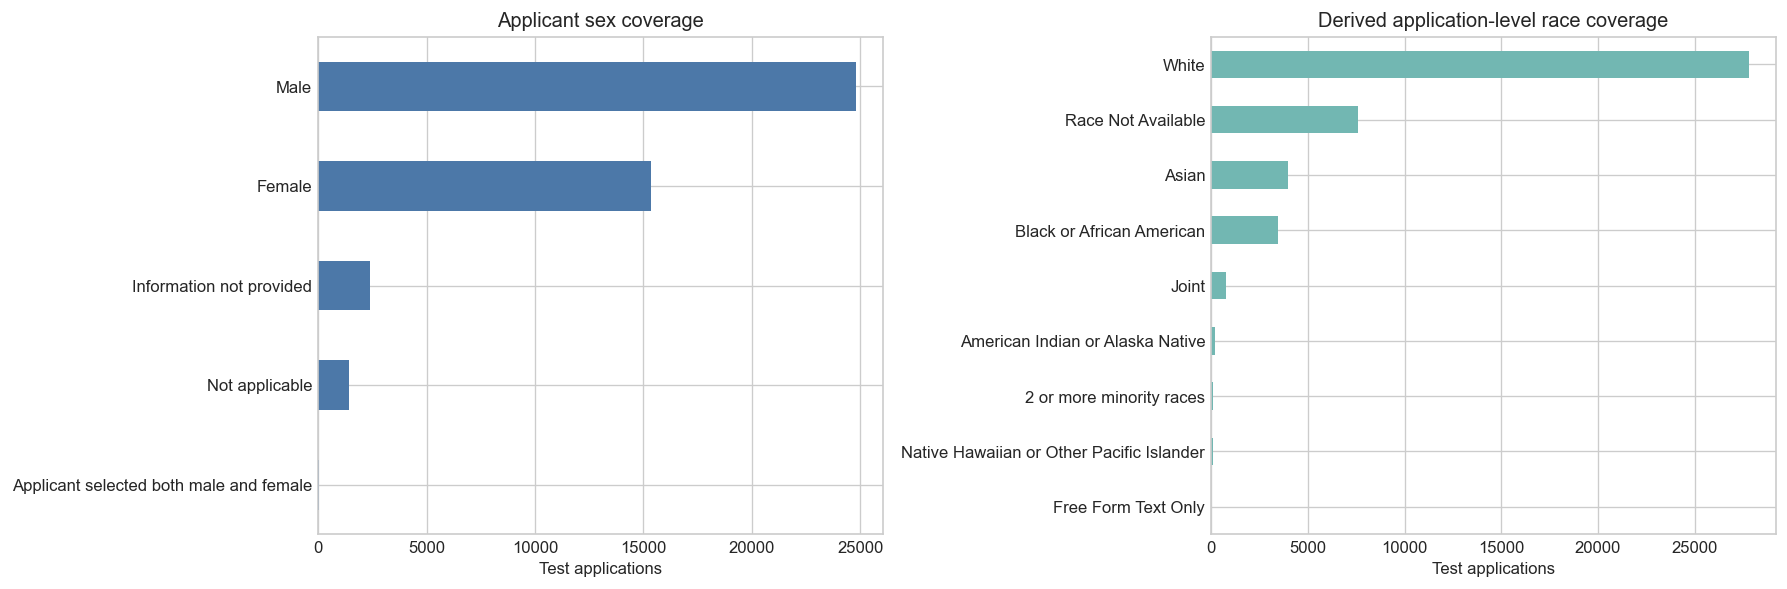

In [2]:
display(runtime.assign(model=runtime["model"].map(MODEL_LABELS)).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sex_counts = audit["applicant_sex_group"].value_counts().sort_values()
race_counts = audit["derived_race"].value_counts().sort_values()
sex_counts.plot.barh(ax=axes[0], color="#4C78A8", title="Applicant sex coverage")
race_counts.plot.barh(ax=axes[1], color="#72B7B2", title="Derived application-level race coverage")
for ax in axes:
    ax.set_xlabel("Test applications")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

## Group rates and outcome denominators

The panels below show the point estimates already stored by the accepted RQ3 run. TPR/FNR use actual Approved applications as their denominator; FPR uses actual Denied applications.

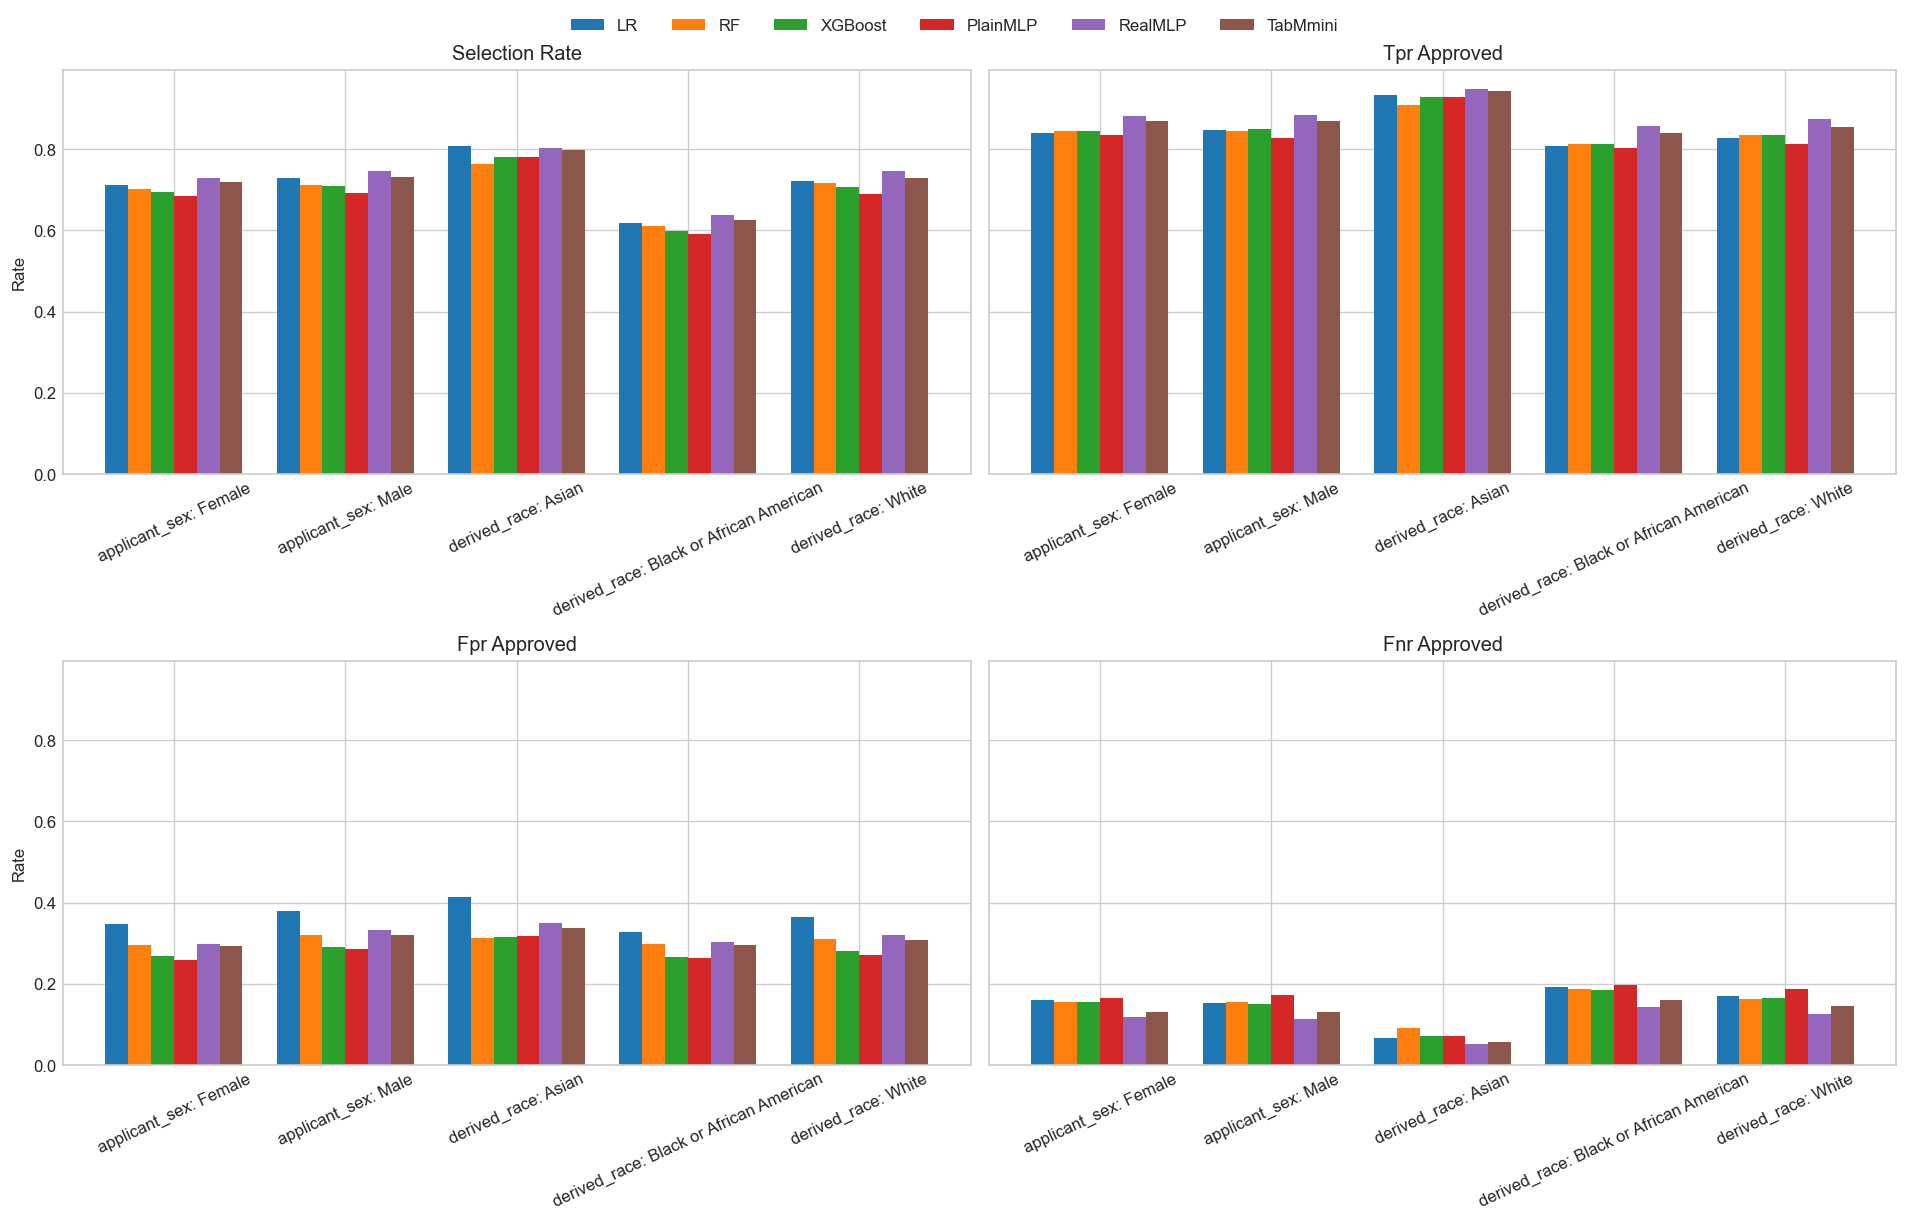

,attribute,group,group_role,group_rows,actual_approved,actual_denied
0,applicant_sex,Applicant selected both male and female,coverage_only,27,15,12
1,applicant_sex,Information not provided,coverage_only,2384,1662,722
2,applicant_sex,Not applicable,coverage_only,1439,1176,263
3,applicant_sex,Female,primary,15347,11355,3992
4,applicant_sex,Male,reference,24799,18607,6192
5,derived_race,Free Form Text Only,coverage_only,21,5,16
6,derived_race,Native Hawaiian or Other Pacific Islander,coverage_only,97,45,52
7,derived_race,Race Not Available,coverage_only,7589,5454,2135
8,derived_race,Asian,primary,3976,3014,962
9,derived_race,Black or African American,primary,3456,2093,1363


In [3]:
rate_metrics = ["selection_rate", "tpr_approved", "fpr_approved", "fnr_approved"]
primary_groups = group_metrics[(group_metrics["status"] == "defined") & (group_metrics["group_role"].isin(["reference", "primary"])) & (group_metrics["metric"].isin(rate_metrics))].copy()
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
for ax, metric in zip(axes.flat, rate_metrics):
    table = primary_groups[primary_groups["metric"] == metric].pivot(index=["attribute", "group"], columns="model", values="value").reindex(columns=MODEL_ORDER)
    table.columns = [MODEL_LABELS[column] for column in table.columns]
    table.index = [f"{attribute}: {group}" for attribute, group in table.index]
    table.plot.bar(ax=ax, width=0.8)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Rate")
    ax.tick_params(axis="x", labelrotation=25)
    ax.legend_.remove()
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(MODEL_ORDER), bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

denominators = group_metrics[group_metrics["metric"] == "selection_rate"][["attribute", "group", "group_role", "group_rows", "actual_approved", "actual_denied"]].drop_duplicates()
display(denominators.sort_values(["attribute", "group_role", "group"]).reset_index(drop=True))

## Pairwise gaps with 95% confidence intervals

Signed gaps use `Female − Male` and race target group `− White`. Negative values indicate a lower metric value for the target group; interpretation therefore depends on the metric. EOD is shown separately because it is an unsigned maximum of the absolute TPR and FPR gaps.

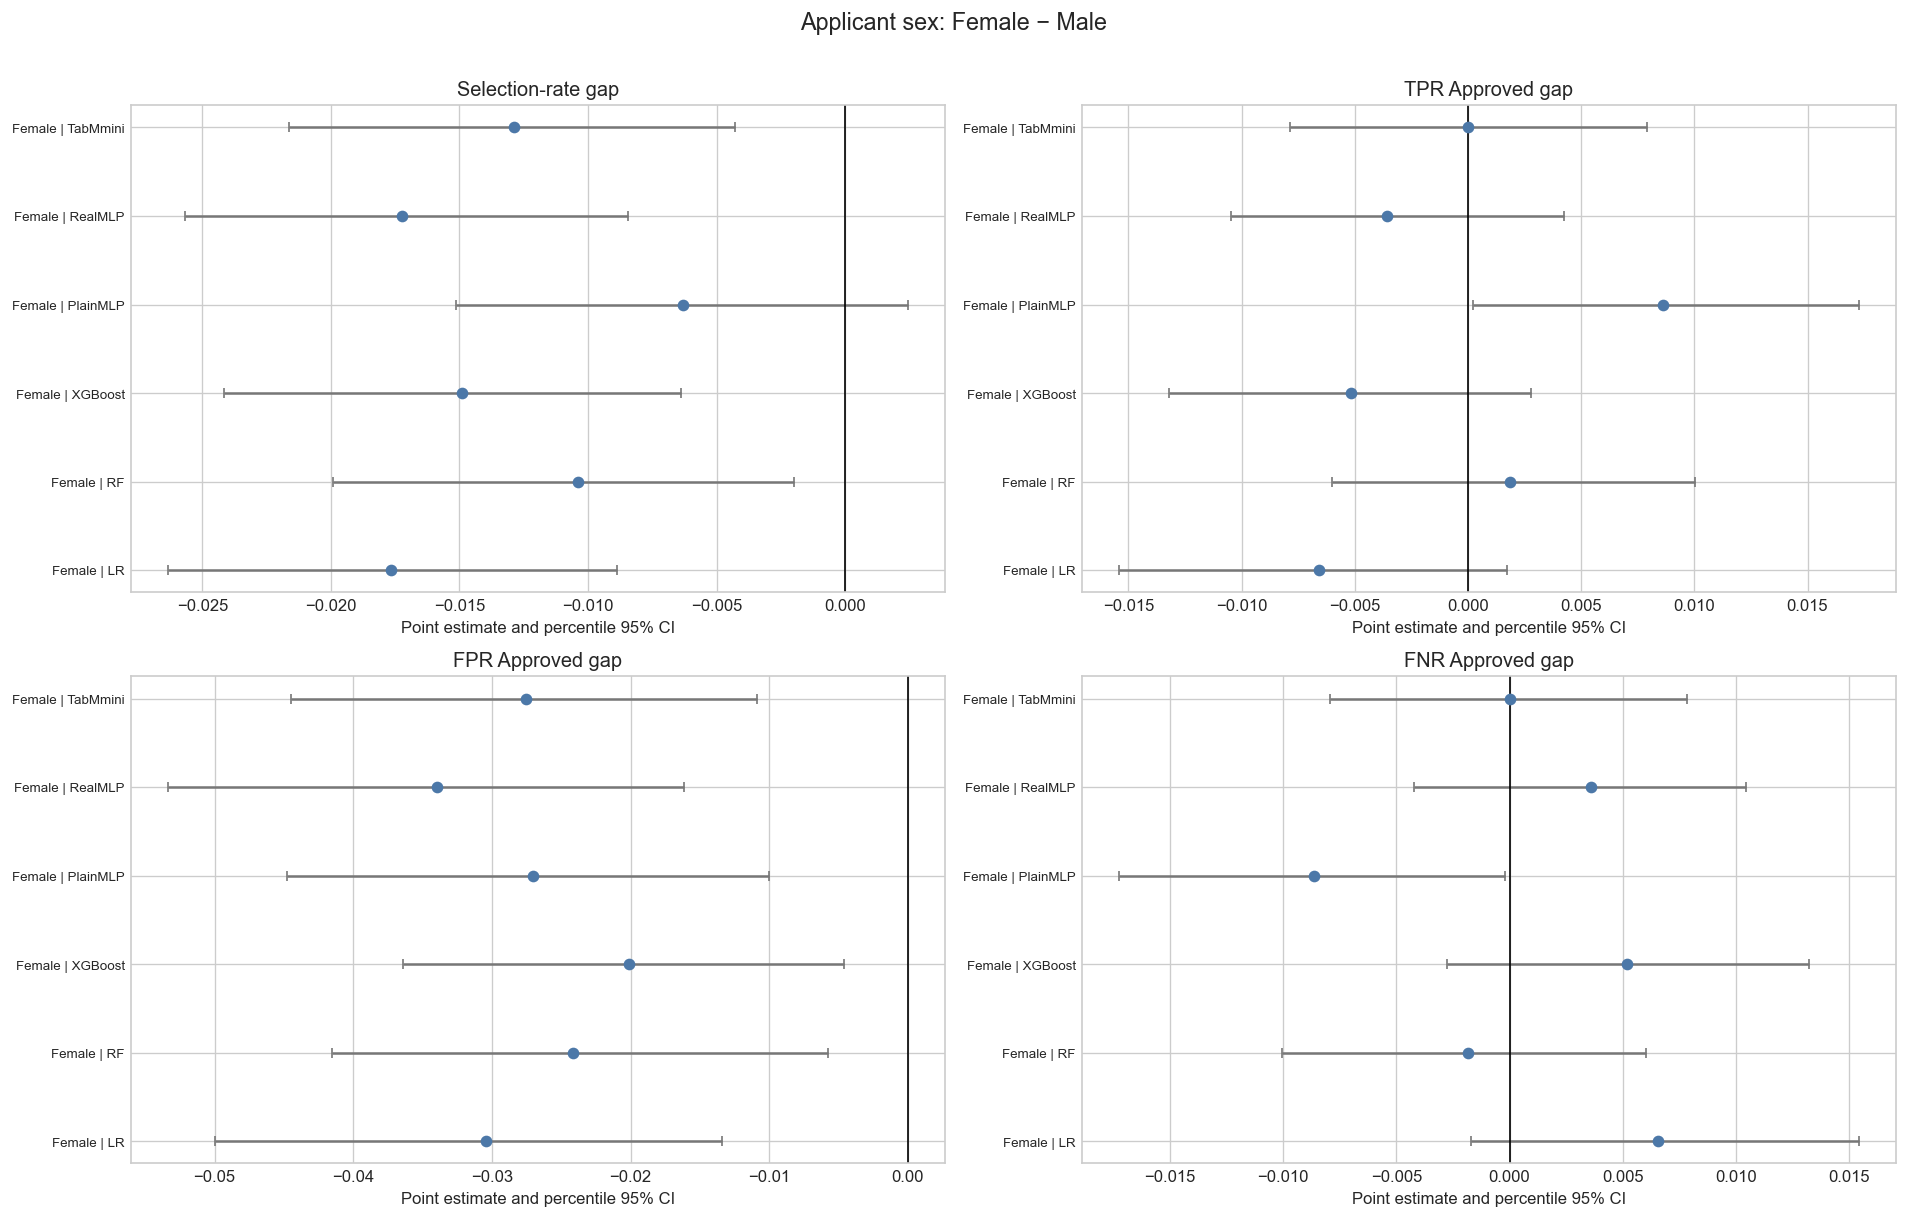

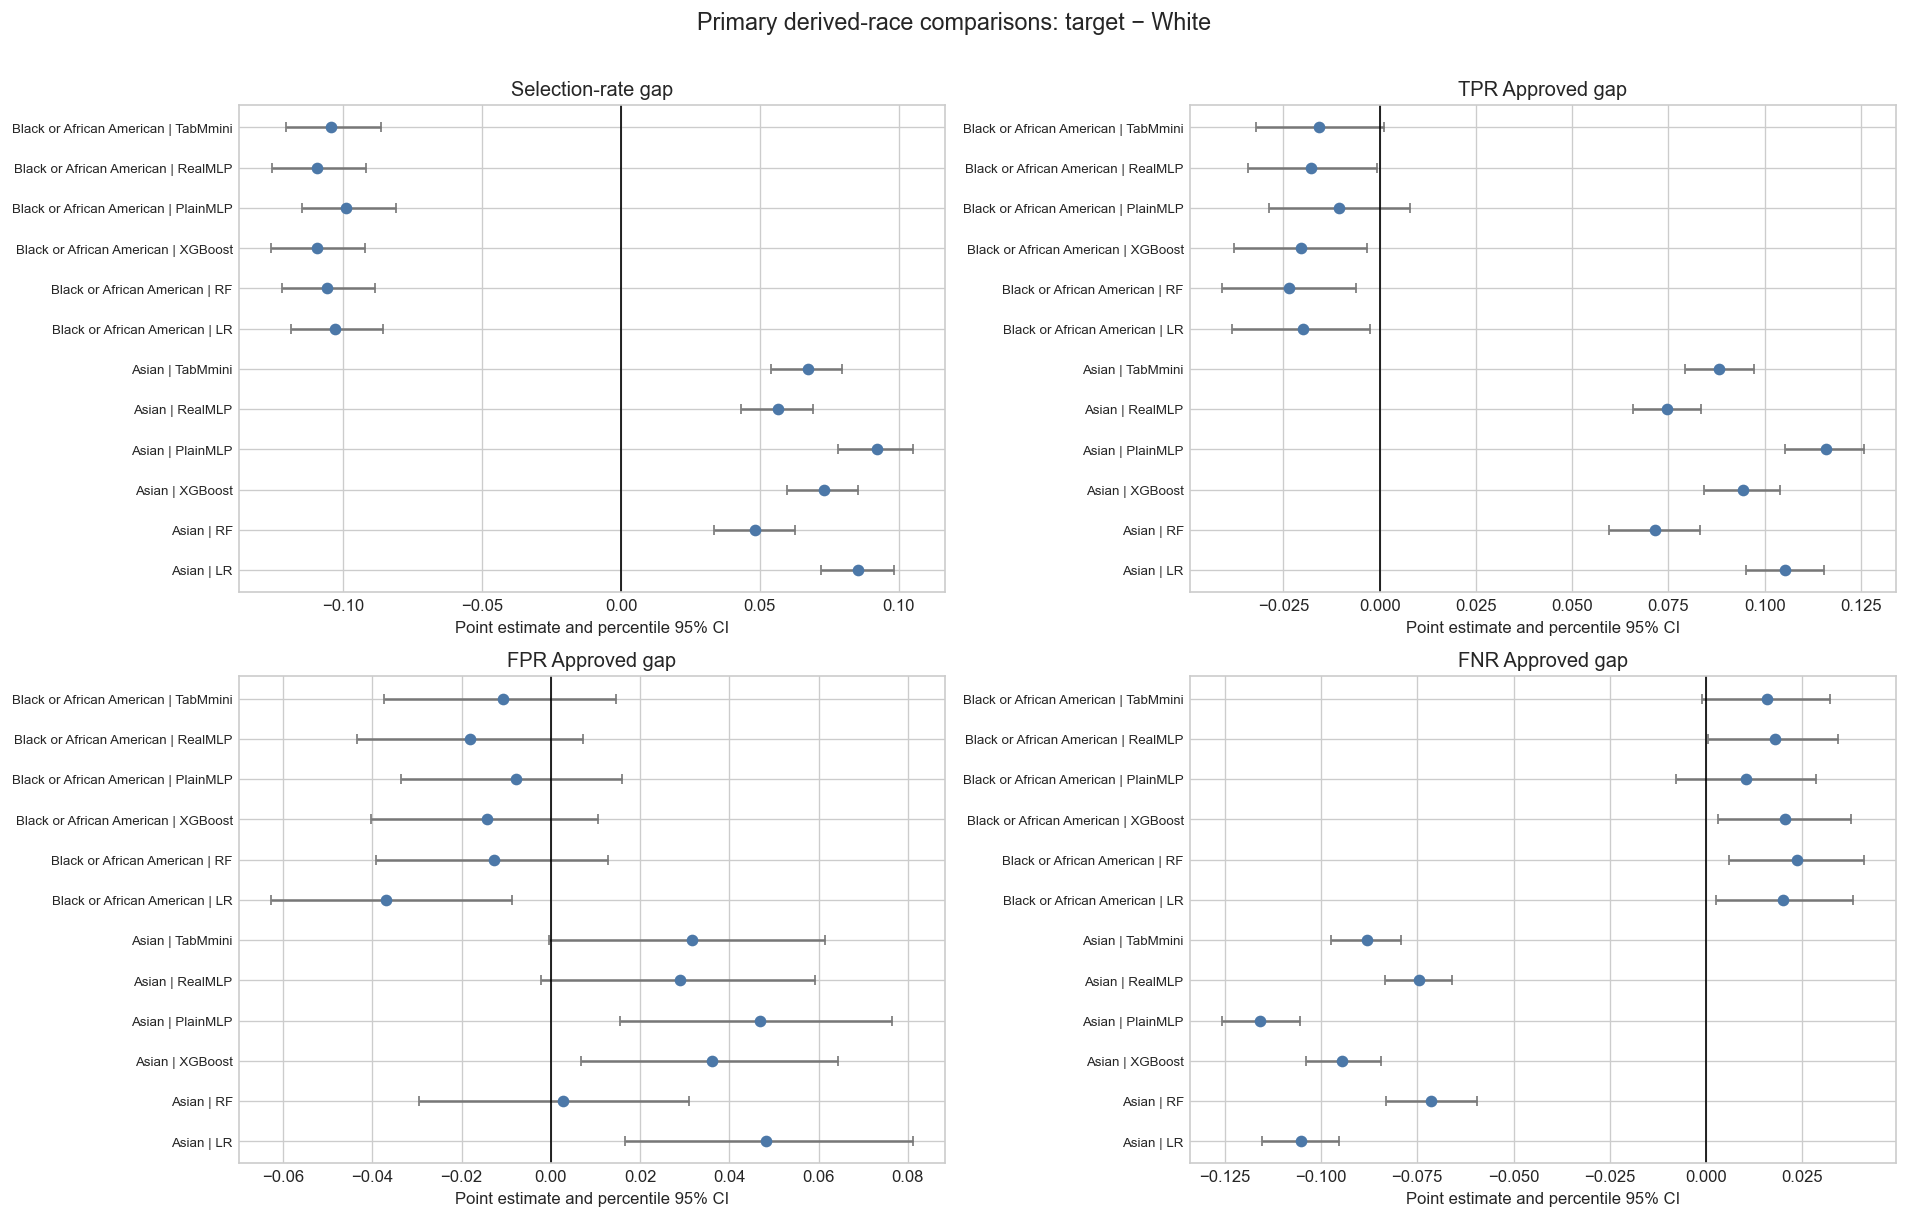

In [4]:
SIGNED_GAPS = ["selection_rate_gap_signed", "tpr_approved_gap_signed", "fpr_approved_gap_signed", "fnr_approved_gap_signed"]
GAP_TITLES = ["Selection-rate gap", "TPR Approved gap", "FPR Approved gap", "FNR Approved gap"]

def plot_gap_grid(frame, figure_title):
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    for ax, metric, title in zip(axes.flat, SIGNED_GAPS, GAP_TITLES):
        panel = frame[(frame["metric"] == metric) & (frame["ci_status"] == "defined")].copy()
        panel["model"] = pd.Categorical(panel["model"], MODEL_ORDER, ordered=True)
        panel = panel.sort_values(["target_group", "model"])
        labels = [f"{row.target_group} | {MODEL_LABELS[str(row.model)]}" for row in panel.itertuples()]
        y = np.arange(len(panel))
        x = panel["point_estimate"].to_numpy()
        err = np.vstack([x - panel["ci_lower"].to_numpy(), panel["ci_upper"].to_numpy() - x])
        ax.errorbar(x, y, xerr=err, fmt="o", color="#4C78A8", ecolor="#777777", capsize=3)
        ax.axvline(0, color="black", linewidth=1)
        ax.set_yticks(y, labels, fontsize=8)
        ax.set_title(title)
        ax.set_xlabel("Point estimate and percentile 95% CI")
    fig.suptitle(figure_title, y=1.01, fontsize=14)
    plt.tight_layout()
    plt.show()

pairwise = bootstrap[bootstrap["result_type"] == "pairwise"]
sex_primary = pairwise[(pairwise["attribute"] == "applicant_sex") & (pairwise["target_group"] == "Female")]
plot_gap_grid(sex_primary, "Applicant sex: Female − Male")

race_primary = pairwise[(pairwise["attribute"] == "derived_race") & (pairwise["target_group"].isin(["Black or African American", "Asian"]))]
plot_gap_grid(race_primary, "Primary derived-race comparisons: target − White")

## Equalized-odds gaps and global race ranges

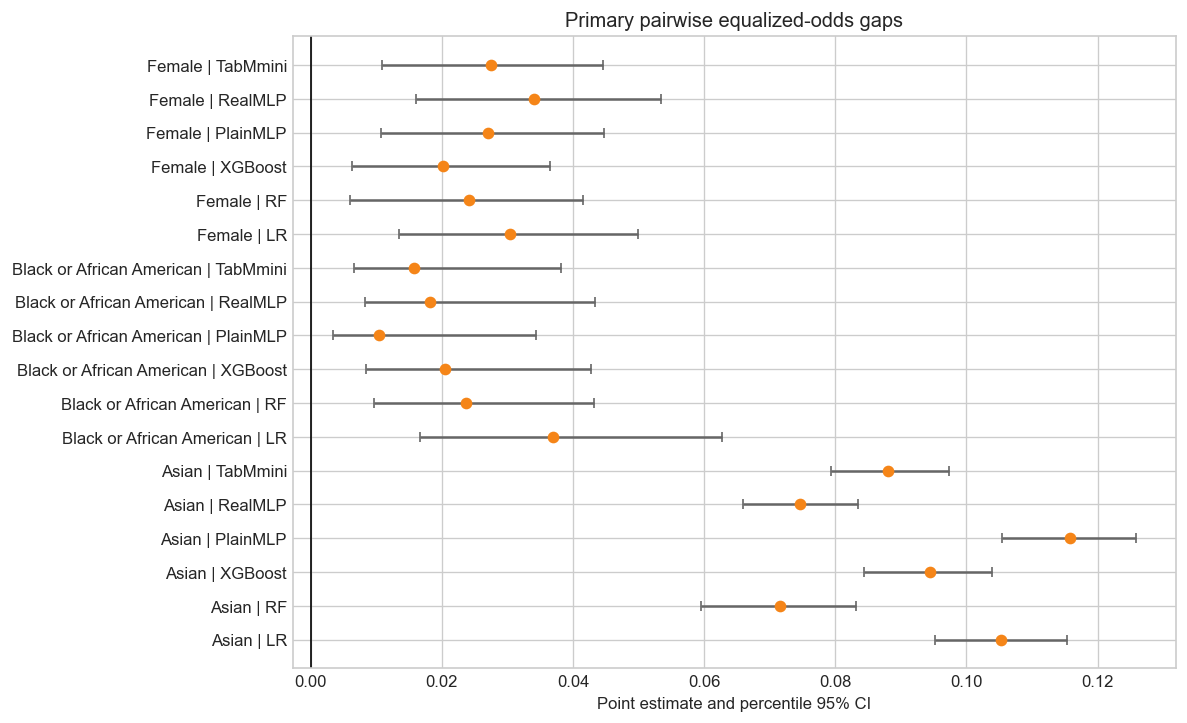

,DPD range,EOD range,FPR range,TPR range
model,,,,
LR,0.2543,0.1982,0.1982,0.1252
RF,0.2845,0.1437,0.1437,0.0961
XGBoost,0.2894,0.1672,0.1672,0.1150
PlainMLP,0.2633,0.1363,0.1363,0.1263
RealMLP,0.2700,0.2072,0.2072,0.0925
TabMmini,0.2747,0.1725,0.1725,0.1038


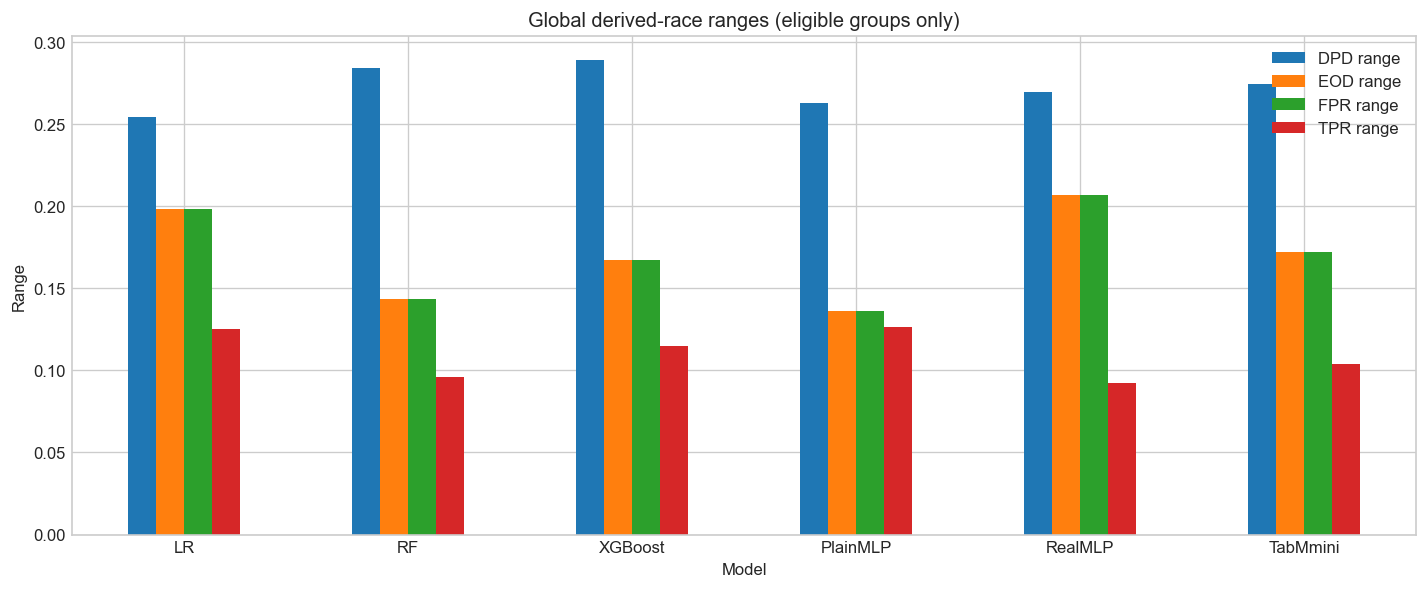

In [5]:
def plot_ci(frame, title, color="#F58518"):
    frame = frame[frame["ci_status"] == "defined"].copy()
    frame["model"] = pd.Categorical(frame["model"], MODEL_ORDER, ordered=True)
    frame = frame.sort_values(["target_group", "model"])
    labels = [f"{row.target_group} | {MODEL_LABELS[str(row.model)]}" for row in frame.itertuples()]
    y = np.arange(len(frame))
    x = frame["point_estimate"].to_numpy()
    err = np.vstack([x - frame["ci_lower"].to_numpy(), frame["ci_upper"].to_numpy() - x])
    fig, ax = plt.subplots(figsize=(10, max(4, 0.34 * len(frame))))
    ax.errorbar(x, y, xerr=err, fmt="o", color=color, ecolor="#666666", capsize=3)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(y, labels)
    ax.set_xlabel("Point estimate and percentile 95% CI")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

eod = pairwise[(pairwise["metric"] == "equalized_odds_gap") & (((pairwise["attribute"] == "applicant_sex") & (pairwise["target_group"] == "Female")) | ((pairwise["attribute"] == "derived_race") & (pairwise["target_group"].isin(["Black or African American", "Asian"]))))]
plot_ci(eod, "Primary pairwise equalized-odds gaps")

global_ranges = gap_metrics[(gap_metrics["result_type"] == "global_range") & (gap_metrics["attribute"] == "derived_race")].pivot(index="model", columns="metric", values="value").reindex(MODEL_ORDER)
global_ranges.index = global_ranges.index.map(MODEL_LABELS)
global_ranges.columns = ["DPD range", "EOD range", "FPR range", "TPR range"]
display(global_ranges.round(4))
global_ranges.plot.bar(figsize=(12, 5), title="Global derived-race ranges (eligible groups only)")
plt.ylabel("Range")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Secondary race groups and CI availability

AI/AN, `2 or more minority races`, and Joint are secondary descriptive comparisons against White. A point estimate may be defined while its bootstrap CI is unavailable when fewer than 950 of 1,000 replicates satisfy the denominator gate. Undefined intervals remain undefined; they are never replaced with zero.

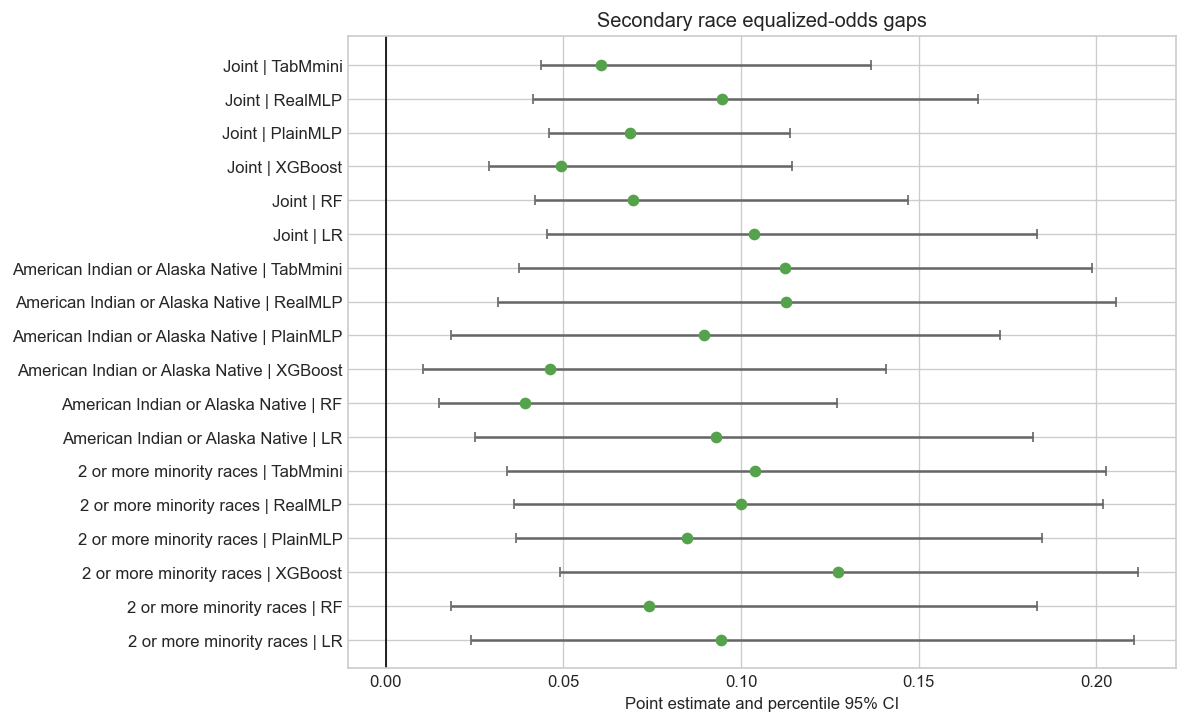

ci_status,Defined CI,Undefined: <950 valid replicates
target_group,,
American Indian or Alaska Native,66,0
2 or more minority races,42,24
Joint,66,0


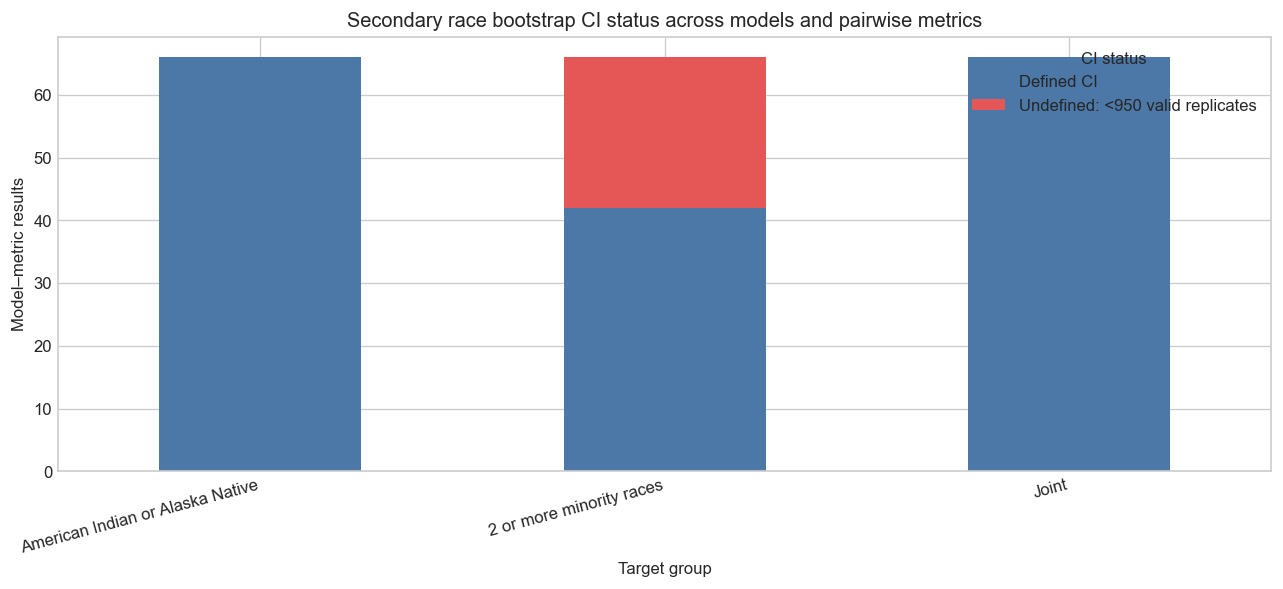

In [6]:
secondary_names = ["American Indian or Alaska Native", "2 or more minority races", "Joint"]
secondary = pairwise[(pairwise["attribute"] == "derived_race") & (pairwise["target_group"].isin(secondary_names))]
plot_ci(secondary[secondary["metric"] == "equalized_odds_gap"], "Secondary race equalized-odds gaps", color="#54A24B")

ci_counts = secondary.groupby(["target_group", "ci_status"]).size().unstack(fill_value=0).reindex(secondary_names)
ci_counts = ci_counts.rename(columns={"defined": "Defined CI", "undefined_insufficient_valid_replicates": "Undefined: <950 valid replicates"})
display(ci_counts)
ax = ci_counts.plot.bar(stacked=True, figsize=(11, 5), color=["#4C78A8", "#E45756"])
plt.title("Secondary race bootstrap CI status across models and pairwise metrics")
plt.xlabel("Target group")
plt.ylabel("Model–metric results")
plt.xticks(rotation=15, ha="right")
ax.legend(title="CI status", loc="upper right")
plt.tight_layout()
plt.show()

## Probability quality by group

Calibration residual is `mean(p_approved − y_approved)`: positive means average predicted approval probability is above the observed approval rate, and negative means it is below. Lower Brier score is better.

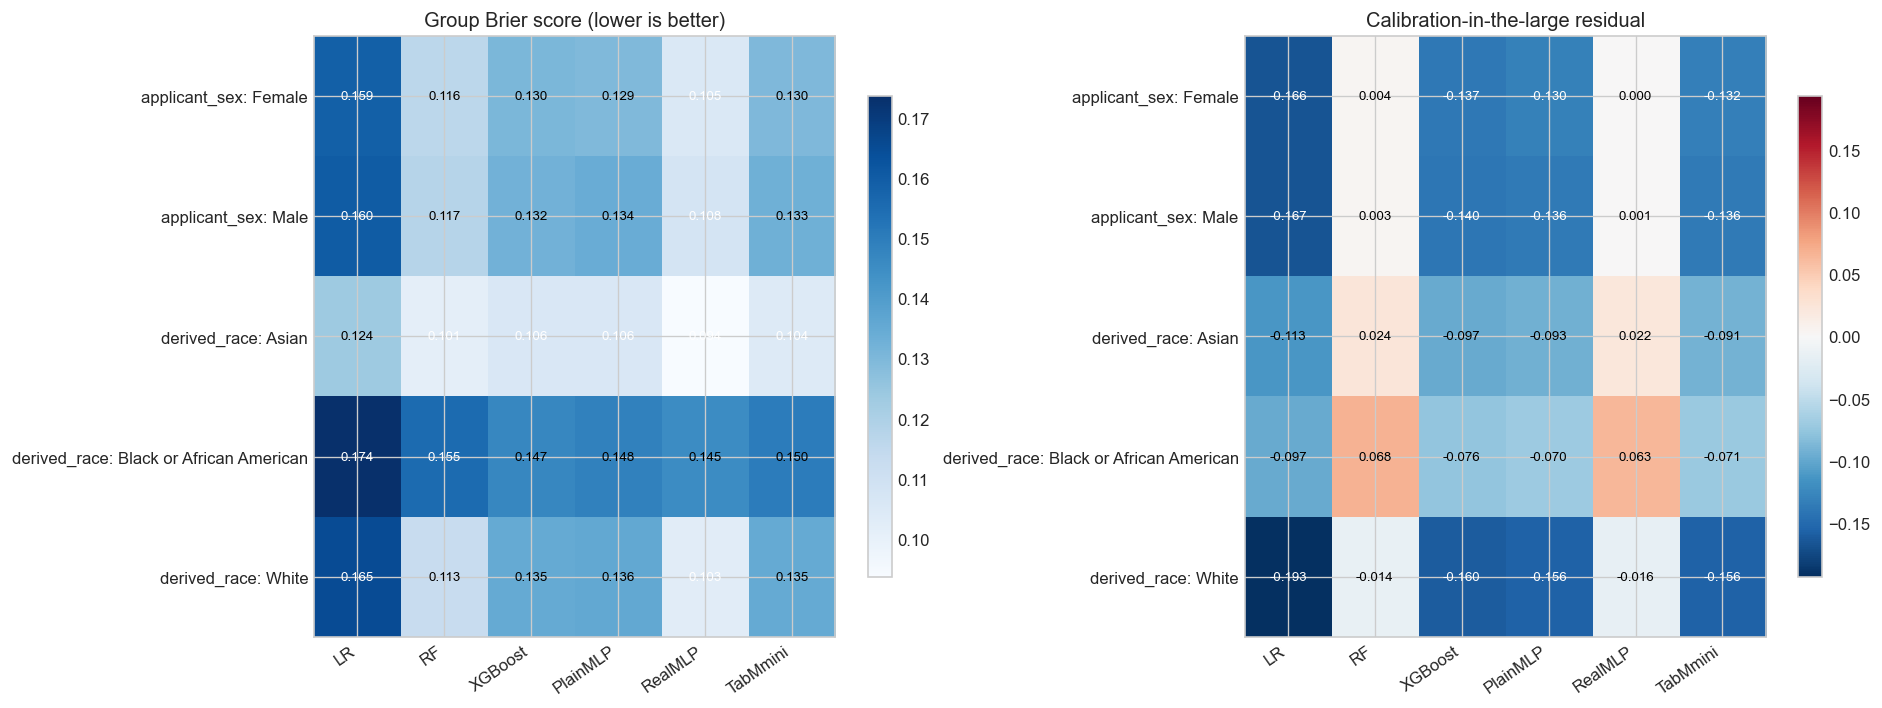

In [7]:
probability_rows = group_metrics[(group_metrics["status"] == "defined") & (group_metrics["group_role"].isin(["reference", "primary"])) & (group_metrics["metric"].isin(["brier_score", "calibration_residual"]))].copy()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, metric, title in zip(axes, ["brier_score", "calibration_residual"], ["Group Brier score (lower is better)", "Calibration-in-the-large residual"]):
    table = probability_rows[probability_rows["metric"] == metric].pivot(index=["attribute", "group"], columns="model", values="value").reindex(columns=MODEL_ORDER)
    table.columns = [MODEL_LABELS[column] for column in table.columns]
    values = table.to_numpy()
    if metric == "brier_score":
        image = ax.imshow(values, aspect="auto", cmap="Blues")
    else:
        limit = np.nanmax(np.abs(values))
        image = ax.imshow(values, aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_xticks(range(len(table.columns)), table.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(table.index)), [f"{a}: {g}" for a, g in table.index])
    ax.set_title(title)
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            normalized = image.norm(values[row, column])
            ax.text(column, row, f"{values[row, column]:.3f}", ha="center", va="center", fontsize=8, color="white" if normalized > 0.72 or normalized < 0.18 else "black")
    fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

## Descriptive performance–fairness comparison

These panels place the accepted RQ1 Test ROC-AUC for Approved beside the accepted RQ3 pairwise EOD values. They are a six-model descriptive comparison only—not evidence of a general performance–fairness trade-off.

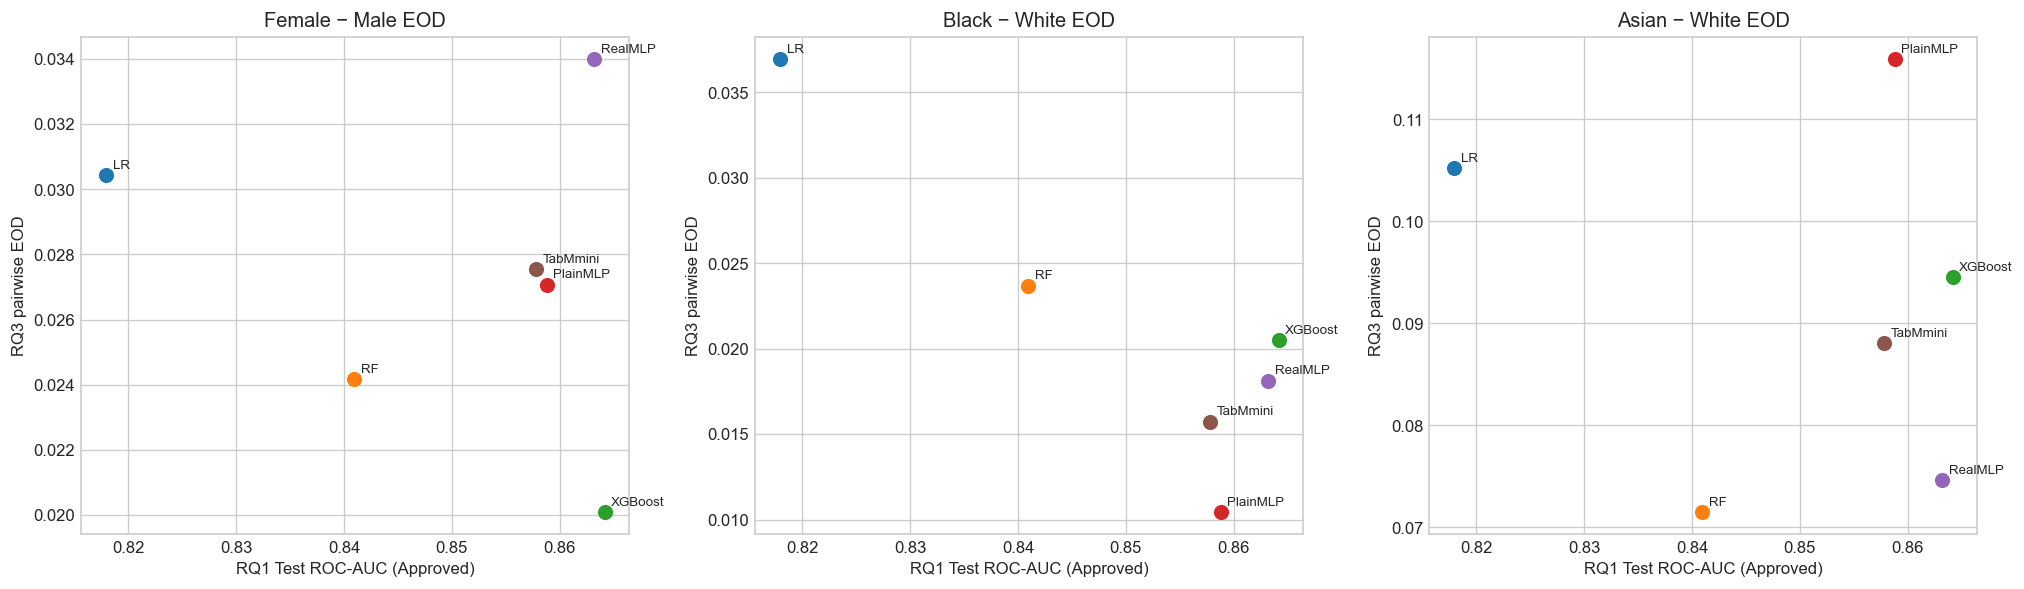

In [8]:
roc_auc = rq1_metrics[(rq1_metrics["partition"] == "test") & (rq1_metrics["metric"] == "roc_auc_approved")].set_index("model_key")["estimate"].reindex(MODEL_ORDER)
eod_points = gap_metrics[(gap_metrics["result_type"] == "pairwise") & (gap_metrics["metric"] == "equalized_odds_gap") & (gap_metrics["status"] == "defined")]
comparisons = [("applicant_sex", "Female", "Female − Male EOD"), ("derived_race", "Black or African American", "Black − White EOD"), ("derived_race", "Asian", "Asian − White EOD")]
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True)
for ax, (attribute, target, title) in zip(axes, comparisons):
    values = eod_points[(eod_points["attribute"] == attribute) & (eod_points["target_group"] == target)].set_index("model")["value"].reindex(MODEL_ORDER)
    for model in MODEL_ORDER:
        ax.scatter(roc_auc.loc[model], values.loc[model], s=65, color=MODEL_COLORS[model])
        ax.annotate(MODEL_LABELS[model], (roc_auc.loc[model], values.loc[model]), xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("RQ1 Test ROC-AUC (Approved)")
    ax.set_ylabel("RQ3 pairwise EOD")
plt.tight_layout()
plt.show()

## Interpretation boundary

These results compare model behavior within the locked Test cohort. Coverage-only groups are retained in the coverage display but excluded from primary gaps and global ranges according to the protocol. Differences are descriptive associations and must not be interpreted as causal effects, applicant creditworthiness, default risk, or legal findings.